Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Файл найден!
Первые 5 строк данных:
            Count
Month            
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Count   144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB
None
Длина ряда: 144


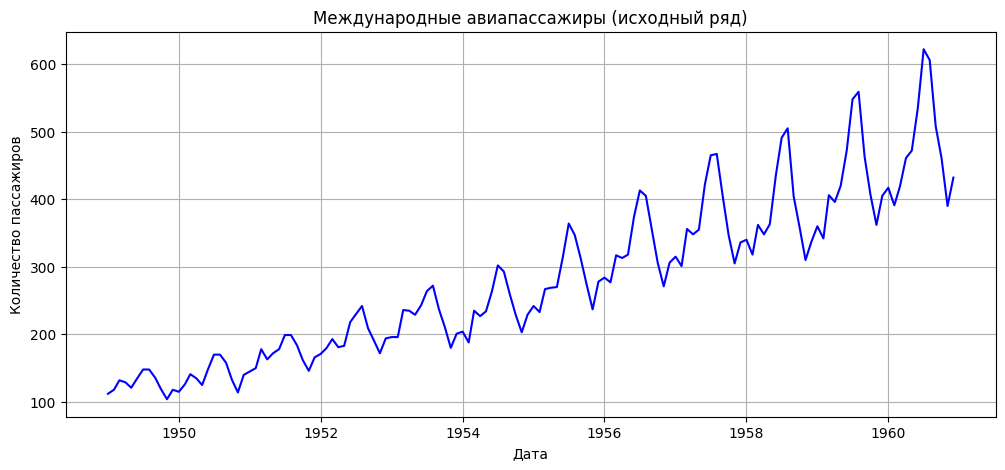

ADF Statistic: 0.8153688792060498
p-value: 0.991880243437641
Critical Values: {'1%': np.float64(-3.4816817173418295), '5%': np.float64(-2.8840418343195267), '10%': np.float64(-2.578770059171598)}
Ряд нестационарен (p-value > 0.05). Требуется дифференцирование.
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=1031.508, Time=0.04 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=1020.393, Time=0.15 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=1021.003, Time=0.23 sec
 ARIMA(1,1,0)(0,1,0)[12]             : AIC=1020.393, Time=0.07 sec
 ARIMA(1,1,0)(2,1,0)[12]             : AIC=1019.239, Time=0.43 sec
 ARIMA(1,1,0)(3,1,0)[12]             : AIC=1020.582, Time=0.79 sec
 ARIMA(1,1,0)(2,1,1)[12]             : AIC=inf, Time=2.91 sec
 ARIMA(1,1,0)(1,1,1)[12]             : AIC=1020.493, Time=0.47 sec
 ARIMA(1,1,0)(3,1,1)[12]             : AIC=inf, Time=8.93 sec
 ARIMA(0,1,0)(2,1,0)[12]             : AIC=1032.120, Time=0.28 sec
 ARIMA(2,1,0)(2,1,0)[12]            

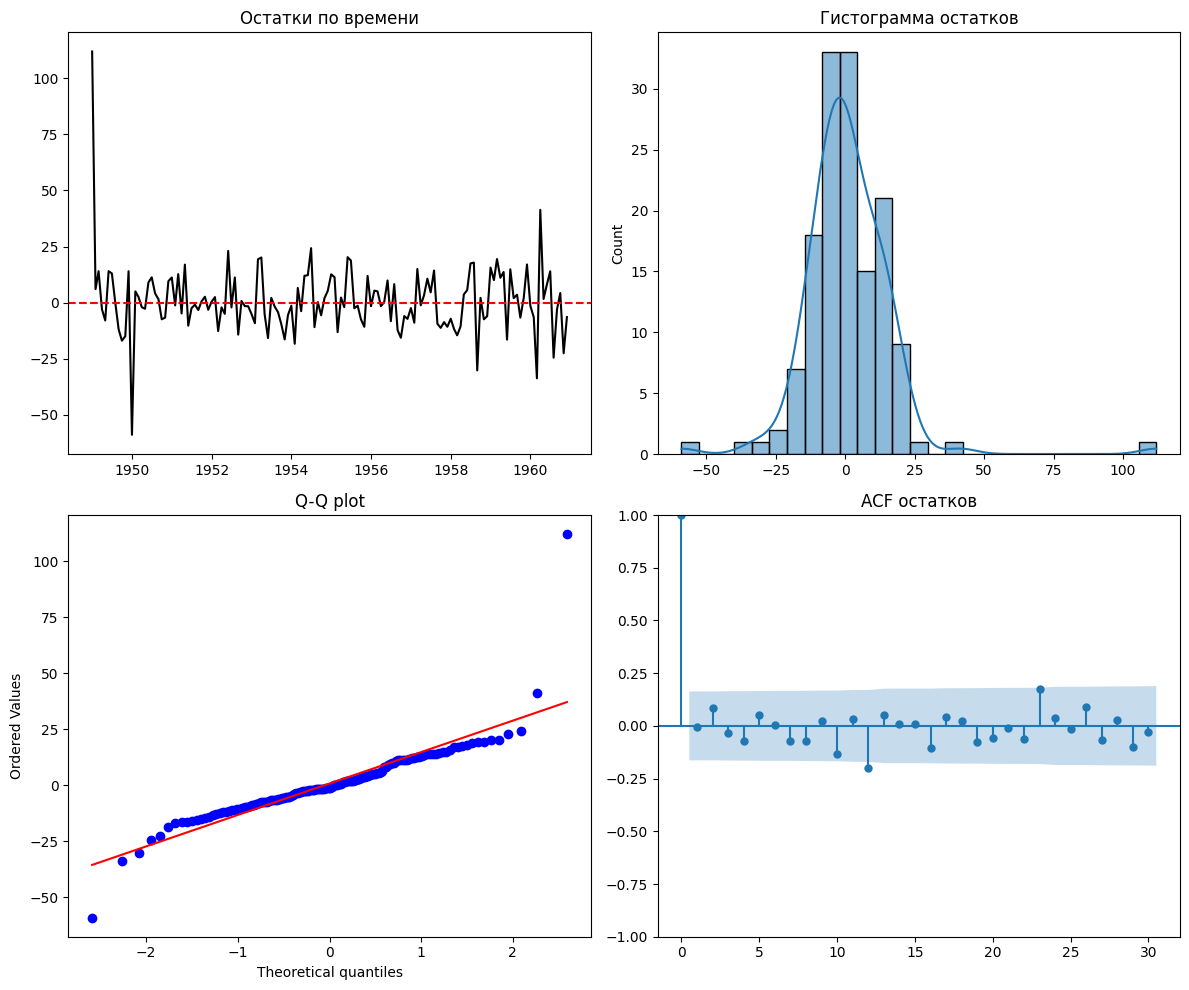

Ljung-Box test p-values:
     lb_stat  lb_pvalue
1   0.004516   0.946419
2   1.049425   0.591725
3   1.221225   0.747918
4   1.997845   0.736155
5   2.373793   0.795370
6   2.378410   0.881820
7   3.177759   0.868086
8   3.974461   0.859420
9   4.066399   0.906988
10  6.769011   0.747057


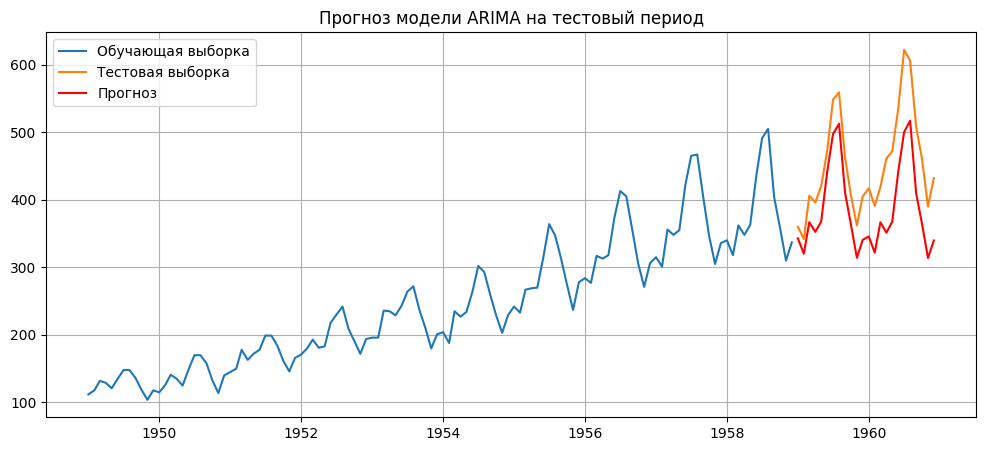

RMSE: 71.87
MAE: 66.00
Размер df_lags_full: (0, 13)
Недостаточно данных для создания лагов. Попробуйте уменьшить количество лагов или увеличить длину ряда.


In [ ]:
!pip install pmdarima

# 1. Подключение Google Drive и импорт библиотек
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
import pmdarima as pm
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from scipy import stats  # <--- правильный импорт
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings('ignore')

# 2. Загрузка данных (файл: international-airline-passengers.csv)
# ПАПКА НАЗЫВАЕТСЯ "Series" (с большой буквы)
file_path = '/content/drive/MyDrive/Series/international-airline-passengers.csv'

import os
if not os.path.exists(file_path):
    raise FileNotFoundError(f"Файл не найден: {file_path}\n"
                            f"Проверьте, что файл лежит в папке 'Series' на Google Диске.")
else:
    print("Файл найден!")

# Чтение CSV: предполагаем, что первая колонка — дата, вторая — значение
df = pd.read_csv(file_path, index_col=0, parse_dates=True)

print("Первые 5 строк данных:")
print(df.head())
print("\nИнформация о данных:")
print(df.info())

# Извлекаем временной ряд (берём первый столбец)
series = df.iloc[:, 0]
print(f"Длина ряда: {len(series)}")

# 3. Визуализация исходного ряда
plt.figure(figsize=(12,5))
plt.plot(series, color='blue')
plt.title('Международные авиапассажиры (исходный ряд)')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров')
plt.grid(True)
plt.show()

# 4. Проверка стационарности (тест Дики-Фуллера)
result = adfuller(series)
print('ADF Statistic:', result[0])
print('p-value:', result[1])
print('Critical Values:', result[4])
if result[1] > 0.05:
    print("Ряд нестационарен (p-value > 0.05). Требуется дифференцирование.")
else:
    print("Ряд стационарен (p-value <= 0.05).")

# 5. Автоматический подбор оптимальных параметров SARIMA
# Для месячных данных сезонный период m = 12
model_auto = pm.auto_arima(
    series,
    start_p=0, start_q=0, max_p=6, max_q=6,
    seasonal=True, m=12,
    start_P=0, start_Q=0, max_P=3, max_Q=3,
    d=None, D=None,                # автоопределение порядка дифференцирования
    trace=True,
    error_action='ignore',
    suppress_warnings=True,
    stepwise=True,
    information_criterion='aic'
)

print("\nОптимальные параметры (p,d,q):", model_auto.order)
print("Оптимальные сезонные параметры (P,D,Q,m):", model_auto.seasonal_order)
print(model_auto.summary())

# 6. Построение модели ARIMA с найденными параметрами
order = model_auto.order
seasonal_order = model_auto.seasonal_order

model = ARIMA(series, order=order, seasonal_order=seasonal_order)
fitted_model = model.fit()
print(fitted_model.summary())

# 7. Диагностика остатков
residuals = fitted_model.resid

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# График остатков по времени
axes[0,0].plot(residuals, color='black')
axes[0,0].axhline(y=0, color='red', linestyle='--')
axes[0,0].set_title('Остатки по времени')

# Гистограмма остатков
sns.histplot(residuals, kde=True, ax=axes[0,1])
axes[0,1].set_title('Гистограмма остатков')

# Q-Q plot (используем scipy.stats)
stats.probplot(residuals, dist="norm", plot=axes[1,0])
axes[1,0].set_title('Q-Q plot')

# ACF остатков
plot_acf(residuals, ax=axes[1,1], lags=30)
axes[1,1].set_title('ACF остатков')

plt.tight_layout()
plt.show()

# тест Льюнга-Бокса на отсутствие автокорреляции
lb_test = acorr_ljungbox(residuals, lags=10, return_df=True)
print("Ljung-Box test p-values:")
print(lb_test)

# 8. Прогнозирование на тестовой выборке (последние 24 месяца)
test_size = 24
train = series[:-test_size]
test = series[-test_size:]

# обучаем модель на тренировочных данных
model_train = ARIMA(train, order=order, seasonal_order=seasonal_order)
fitted_train = model_train.fit()

# прогноз
forecast = fitted_train.forecast(steps=len(test))
forecast_index = test.index

# визуализация прогноза
plt.figure(figsize=(12,5))
plt.plot(train.index, train, label='Обучающая выборка')
plt.plot(test.index, test, label='Тестовая выборка')
plt.plot(forecast_index, forecast, label='Прогноз', color='red')
plt.title('Прогноз модели ARIMA на тестовый период')
plt.legend()
plt.grid(True)
plt.show()

# метрики качества
rmse = np.sqrt(mean_squared_error(test, forecast))
mae = mean_absolute_error(test, forecast)
print(f'RMSE: {rmse:.2f}')
print(f'MAE: {mae:.2f}')

# 9. ДОПОЛНИТЕЛЬНОЕ ЗАДАНИЕ: модель Random Forest на лагах (с проверками)
def create_lag_features(data, lags=12):
    df = pd.DataFrame(data, columns=['y'])
    for lag in range(1, lags+1):
        df[f'lag_{lag}'] = df['y'].shift(lag)
    df.dropna(inplace=True)
    return df

# параметры
lags = 12
test_size_ml = 24

df_lags_full = create_lag_features(series, lags=lags)
print(f"Размер df_lags_full: {df_lags_full.shape}")

if df_lags_full.empty:
    print("Недостаточно данных для создания лагов. Попробуйте уменьшить количество лагов или увеличить длину ряда.")
else:
    X_full = df_lags_full.drop('y', axis=1)
    y_full = df_lags_full['y']

    if len(X_full) <= test_size_ml:
        print(f"Недостаточно данных для разделения на train/test (нужно > {test_size_ml}). Уменьшите test_size_ml.")
    else:
        X_train = X_full[:-test_size_ml]
        X_test = X_full[-test_size_ml:]
        y_train = y_full[:-test_size_ml]
        y_test = y_full[-test_size_ml:]

        print(f"Размер обучающей выборки ML: {len(X_train)}, тестовой: {len(X_test)}")
        print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

        # масштабирование
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # обучение Random Forest
        rf = RandomForestRegressor(n_estimators=100, random_state=42)
        rf.fit(X_train_scaled, y_train)

        # прогноз и оценка
        pred_rf = rf.predict(X_test_scaled)
        rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))
        mae_rf = mean_absolute_error(y_test, pred_rf)
        print(f'Random Forest RMSE: {rmse_rf:.2f}, MAE: {mae_rf:.2f}')

        # визуализация прогноза ML
        plt.figure(figsize=(12,5))
        plt.plot(y_test.index, y_test, label='Факт')
        plt.plot(y_test.index, pred_rf, label='Прогноз Random Forest', color='green')
        plt.title('Прогноз Random Forest на тестовой выборке')
        plt.legend()
        plt.grid(True)
        plt.show()